# Exploratory data analysis

In this project, we build an end-to-end machine learning pipeline to predict hotel booking outcomes, with the goal of identifying bookings that may result in a no-show. This exploratory data analysis will aid in data understanding, thus informing the construction of the end-to-end machine learning pipeline, in particular the data preparation steps prior to model training.

We begin with preliminary data exploration, followed by univariate data analysis, and then bivariate data analysis, which focuses on relationships between booking features and the no-show outcome.


## 1. Preliminary data exploration

Inspect the first few rows to get an intuition for the data.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import chi2_contingency, mannwhitneyu

pd.set_option("display.max_columns", 100)
plt.style.use("seaborn-v0_8-whitegrid")

candidate_roots = [Path.cwd(), Path.cwd() / "ts", Path.cwd().parent]
PROJECT_ROOT = next(
    root for root in candidate_roots
    if (root / "data" / "raw" / "noshow.db").exists()
)
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "noshow.db"
TABLE_NAME = "noshow"
TARGET_COLUMN = "no_show"

if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.append(str(PROJECT_ROOT / "src"))

from hotel_no_show_prediction.pipelines.data_ingestion.nodes import load_raw_noshow

raw_df = load_raw_noshow({
    "path": str(DATA_PATH),
    "table_name": TABLE_NAME,
})
df = raw_df.copy()
raw_df.head()


,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children
0,94113,0.0,Changi,November,June,25.0,June,27.0,Singapore,Yes,Single,SGD$ 492.98,Website,1,0.0
1,86543,0.0,Orchard,August,November,28.0,November,29.0,Indonesia,Yes,King,SGD$ 1351.22,Website,2,0.0
2,75928,0.0,Changi,March,February,7.0,February,11.0,India,Yes,Single,None,Agent,1,0.0
3,66947,1.0,Orchard,September,October,1.0,October,3.0,China,Yes,Single,SGD$ 666.04,Website,1,0.0
4,106390,0.0,Orchard,March,June,20.0,June,24.0,Australia,Yes,Queen,USD$ 665.37,Website,1,0.0


In [2]:
print("Dataset dimensions:", df.shape)
print("Column names:", df.columns.tolist())

Dataset dimensions: (119391, 15)
Column names: ['booking_id', 'no_show', 'branch', 'booking_month', 'arrival_month', 'arrival_day', 'checkout_month', 'checkout_day', 'country', 'first_time', 'room', 'price', 'platform', 'num_adults', 'num_children']


The raw table contains 119,391 booking rows and 15 columns. The column names are shown below. Its fields represent booking identifiers, the no-show target, booking and stay calendar components, guest information, room and price details, and booking platform.


### 1.1 Preliminary data exploration by columns

The columns are categorised as follows based on our expectations:


In [3]:
identifiers = ["booking_id"]
numeric_integer_features = [
    "arrival_day",
    "checkout_day",
    "num_adults",
    "num_children",
]
numeric_float_features = ["price"]
categorical_nominal_features = [
    "branch",
    "booking_month",
    "arrival_month",
    "checkout_month",
    "country",
    "first_time",
    "room",
    "platform",
]
categorical_plot_features = categorical_nominal_features.copy()
datetime_features = []
target = [TARGET_COLUMN]

category_to_column_dict = {
    "identifier": identifiers,
    "numeric_integer": numeric_integer_features,
    "numeric_float": numeric_float_features,
    "categorical_nominal": categorical_nominal_features,
    "datetime": datetime_features,
    "target": target,
}
category_to_column_dict


{'identifier': ['booking_id'],
 'numeric_integer': ['arrival_day',
  'checkout_day',
  'num_adults',
  'num_children'],
 'numeric_float': ['price'],
 'categorical_nominal': ['branch',
  'booking_month',
  'arrival_month',
  'checkout_month',
  'country',
  'first_time',
  'room',
  'platform'],
 'datetime': [],
 'target': ['no_show']}

Information regarding each column is summarised below.


In [4]:
column_to_category_dict = {
    column: category
    for category, columns in category_to_column_dict.items()
    for column in columns
}

expected_dtype_by_category = {
    "identifier": "any",
    "numeric_integer": "int64",
    "numeric_float": "float64",
    "categorical_nominal": "object",
    "datetime": "datetime64[ns]",
    "target": "int64",
}

columns_summary = pd.DataFrame({
    "column": df.columns,
    "category": [
        column_to_category_dict.get(column, "uncategorized")
        for column in df.columns
    ],
    "dtype": df.dtypes.astype(str).values,
    "expected_dtype": [
        expected_dtype_by_category.get(
            column_to_category_dict.get(column, "uncategorized"),
            "uncategorized",
        )
        for column in df.columns
    ],
    "null_count": df.isna().sum().values,
    "null_rate": df.isna().mean().values,
})

columns_summary.sort_values("category")


,column,category,dtype,expected_dtype,null_count,null_rate
2,branch,categorical_nominal,object,object,1,0.000008
3,booking_month,categorical_nominal,object,object,1,0.000008
4,arrival_month,categorical_nominal,object,object,1,0.000008
6,checkout_month,categorical_nominal,object,object,1,0.000008
8,country,categorical_nominal,object,object,1,0.000008
9,first_time,categorical_nominal,object,object,1,0.000008
10,room,categorical_nominal,object,object,21613,0.181027
12,platform,categorical_nominal,object,object,1,0.000008
0,booking_id,identifier,int64,any,0,0.000000
11,price,numeric_float,object,float64,24882,0.208408


Inspecting the column summary informs the following decisions:

| Area | Expected type | Current raw type | Cleaning implication or next investigation |
| --- | --- | --- | --- |
| Target representation | `no_show` should be a binary integer target. | `no_show` is stored as `float64` and has 1 missing value. | Use `drop_missing_target_rows` to remove the missing target row, then use `convert_numeric_column_types` to cast the target to nullable `Int64`. |
| Numeric representations | `arrival_day`, `checkout_day`, `num_adults`, and `num_children` should be integer features. | `arrival_day`, `checkout_day`, and `num_children` are stored as `float64` and each has 1 missing value; `num_adults` is stored as an object field and has 1 missing value. | Inspect the observed values, then standardise and cast to nullable integers. |
| Price representation | `price` should become a numeric monetary feature with currency handled separately. | `price` is stored as an object field and has 24,882 missing values. | Inspect price strings and currencies before parsing and deciding how to retain missing values. |
| Calendar values | `arrival_day` and `checkout_day` should be valid integer day-of-month values. | Both are stored as `float64` fields and each has 1 missing value. | Check day ranges before casting and constructing calendar and stay-length features. |
| Missing values | Missing values should be identified before cleaning and handled according to each field's role. | `no_show`, `branch`, `booking_month`, `arrival_month`, `arrival_day`, `checkout_month`, `checkout_day`, `country`, `first_time`, `platform`, `num_adults`, and `num_children` each have 1 missing value; `room` has 21,613; `price` has 24,882; `booking_id` has none. | Since the singleton missing values affect only one row per field, use `drop_rows_with_low_missingness` to drop those rows. Retain the higher-missingness `room` and `price` fields for separate downstream treatment. |


### 1.2 Preliminary data exploration by rows

Inspect duplicate entries based on the booking identifier and complete rows.


In [5]:
df["booking_id"].duplicated().sum(), df.duplicated().sum()


(0, 0)

In [6]:
# show examples when duplicate booking identifiers exist
df[df["booking_id"].duplicated(keep=False)].sort_values("booking_id").head()


,booking_id,no_show,branch,booking_month,arrival_month,arrival_day,checkout_month,checkout_day,country,first_time,room,price,platform,num_adults,num_children


## 2. Conversion to expected type

Convert the raw fields to their expected types so that the subsequent univariate data analysis can use the intended numeric features and their observed values.


### 2.1 Conversion to integer type

Inspect the raw types needed before converting the expected integer fields.


In [7]:
integer_conversion_columns = identifiers + target + numeric_integer_features
integer_conversion_columns


['booking_id',
 'no_show',
 'arrival_day',
 'checkout_day',
 'num_adults',
 'num_children']

In [8]:
raw_df[integer_conversion_columns].dtypes.astype(str)


booking_id        int64
no_show         float64
arrival_day     float64
checkout_day    float64
num_adults       object
num_children    float64
dtype: object

In [9]:
raw_df["no_show"].value_counts(dropna=False)

no_show
0.0    75166
1.0    44224
NaN        1
Name: count, dtype: int64

In [10]:
day_columns = ["arrival_day", "checkout_day"]
{
    column: {
        "all_integer": raw_df[column].dropna().mod(1).eq(0).all(),
    }
    for column in day_columns
}


{'arrival_day': {'all_integer': True}, 'checkout_day': {'all_integer': True}}

In [11]:
raw_df["num_adults"].value_counts(dropna=False)


num_adults
1       62745
2       45243
one      6334
two      5068
None        1
Name: count, dtype: int64

Inspecting the integer types informs the following conversions:

| Field | Finding | Cleaning action |
| --- | --- | --- |
| `num_adults` | 11,402 values are words (`one` or `two`). | Use `num_adults_words_to_numbers` to replace the word forms with numeric strings (`1` or `2`), then use `convert_numeric_column_types` to cast the expected integer fields to nullable `Int64` dtypes. |
| `no_show`, `arrival_day`, `checkout_day`, and `num_children` | Their observed non-missing values are integer-valued, although the raw fields are stored as `float64`. | Use `convert_numeric_column_types` directly to cast these fields to nullable `Int64` dtypes. |


In [12]:
from hotel_no_show_prediction.pipelines.data_cleaning.nodes import (
    convert_numeric_column_types,
    num_adults_words_to_numbers,
)

df = num_adults_words_to_numbers(df)
df = convert_numeric_column_types(df)


### 2.2 Conversion to float type

Inspect the raw price representation before creating its numeric amount.


The price pattern allows optional surrounding whitespace, requires either `SGD` or `USD`, requires a literal `$`, and then requires a numeric amount with an optional decimal part. Because the code uses `fullmatch`, the entire non-missing value must follow this pattern. For example, `SGD$ 492.98` and `USD$ 665.37` match, while `SGD 492.98` (missing `$`), `EUR$ 492.98` (unsupported currency), and `SGD$ unknown` (non-numeric amount) do not.


In [13]:
price_pattern = r"\s*(?:SGD|USD)\$\s*\d+(?:\.\d+)?\s*"
price_matches = raw_df["price"].astype("string").str.fullmatch(price_pattern)


In [14]:
price_matches.value_counts(dropna=False)

price
True    94509
<NA>    24882
Name: count, dtype: Int64

In [15]:
price_matches[raw_df["price"].notna()].value_counts(dropna=False)

price
True    94509
Name: count, dtype: Int64

In [16]:
int((raw_df["price"].notna() & ~price_matches.fillna(False)).sum())


0

Inspecting the price representation informs the following conversion:

| Field | Finding | Cleaning action |
| --- | --- | --- |
| `price` | The specified SGD/USD price pattern matches every non-missing value, with no non-missing parse failures. | Use `parse_price_currency_and_amount` *(feature-engineering node)* to split the currency label into `price_currency` and parse the numeric amount into `price_amount`. |


In [17]:
from hotel_no_show_prediction.pipelines.feature_engineering.nodes import (
    parse_price_currency_and_amount,)

df = parse_price_currency_and_amount(df)


In [18]:
post_cleaning_sanity_check = {
    "integer_dtypes": df[integer_conversion_columns].dtypes.astype(str),
    "num_adults_values": df["num_adults"].value_counts(dropna=False),
    "price_amount_dtype": str(df["price_amount"].dtype),
}
post_cleaning_sanity_check


{'integer_dtypes': booking_id      Int64
 no_show         Int64
 arrival_day     Int64
 checkout_day    Int64
 num_adults      Int64
 num_children    Int64
 dtype: object,
 'num_adults_values': num_adults
 1       69079
 2       50311
 <NA>        1
 Name: count, dtype: Int64,
 'price_amount_dtype': 'Float64'}

## 3. Univariate data analysis

### 3.1 Univariate data analysis for numeric features and the target variable

Inspecting summary statistics for numeric features and the no-show target.


In [19]:
numeric_analysis_df = df[
    numeric_integer_features + target
].copy()
numeric_analysis_df["price"] = df["price_amount"]
numeric_analysis_df[numeric_integer_features + numeric_float_features + target].describe().T


,count,mean,std,min,25%,50%,75%,max
arrival_day,119390.0,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
checkout_day,119390.0,14.250507,11.063697,-31.0,7.0,15.0,23.0,31.0
num_adults,119390.0,1.4214,0.493786,1.0,1.0,1.0,2.0,2.0
num_children,119390.0,0.871229,0.779796,0.0,0.0,1.0,1.0,3.0
price,94509.0,821.181948,266.067849,292.01,636.79,815.32,957.57,2099.96
no_show,119390.0,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0


The numeric summary shows negative day values, so inspect their counts and examples before plotting the numeric features.


In [20]:
negative_day_table = pd.DataFrame(
    {
        "negative_count": (df[day_columns] < 0).sum(),
        "negative_examples": [
            df.loc[df[column] < 0, column].head().tolist()
            for column in day_columns
        ],
    }
)
negative_day_table


,negative_count,negative_examples
arrival_day,0,[]
checkout_day,5696,"[-4, -10, -3, -6, -5]"


The summary statistics and plots for numeric features and the target variable inform the following decisions:

| Field | Finding | Cleaning action |
| --- | --- | --- |
| `checkout_day` | `numeric_analysis_df` shows a minimum value of `-31`, and the negative-day investigation identifies negative observations. | Use `set_invalid_day_of_month_to_missing` to set invalid day-of-month values, including negative values, to missing before plotting and feature construction. |


In [21]:
from hotel_no_show_prediction.pipelines.data_cleaning.nodes import (
    set_invalid_day_of_month_to_missing,
)

df = set_invalid_day_of_month_to_missing(df)

numeric_analysis_df = df[numeric_integer_features + target].copy()
numeric_analysis_df["price"] = df["price_amount"]


In [22]:
post_cleaning_sanity_check = {
    "integer_dtypes": df[integer_conversion_columns].dtypes.astype(str),
    "price_amount_dtype": str(df["price_amount"].dtype),
    "negative_day_counts": (df[day_columns] < 0).sum(),
}
post_cleaning_sanity_check


{'integer_dtypes': booking_id      Int64
 no_show         Int64
 arrival_day     Int64
 checkout_day    Int64
 num_adults      Int64
 num_children    Int64
 dtype: object,
 'price_amount_dtype': 'Float64',
 'negative_day_counts': arrival_day     0
 checkout_day    0
 dtype: Int64}

Inspecting barplots and histograms for numeric features and the no-show target.


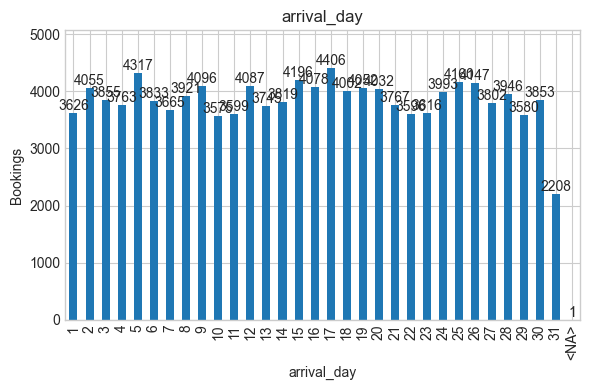

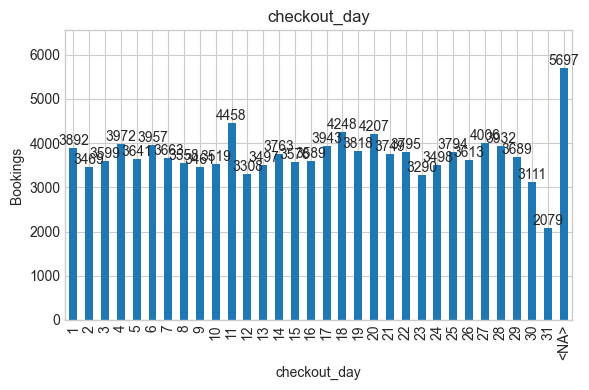

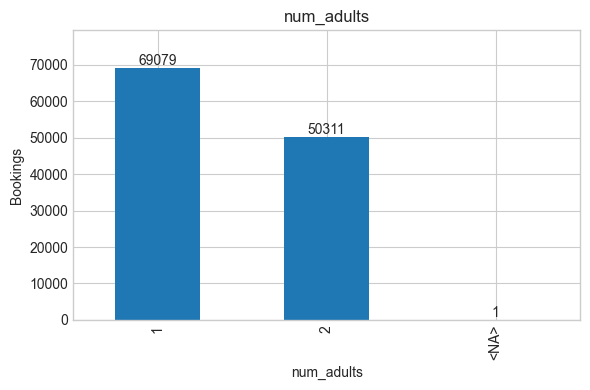

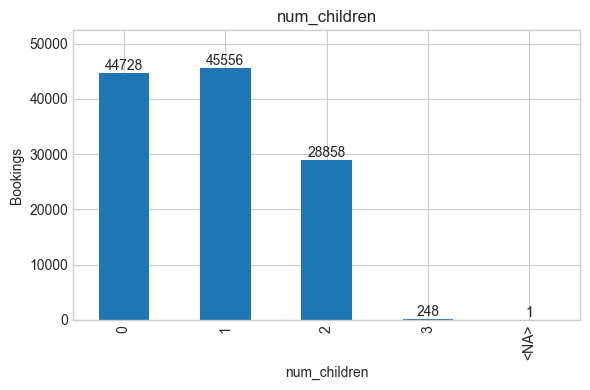

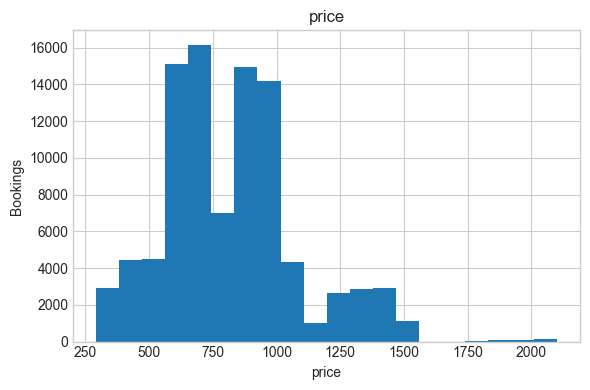

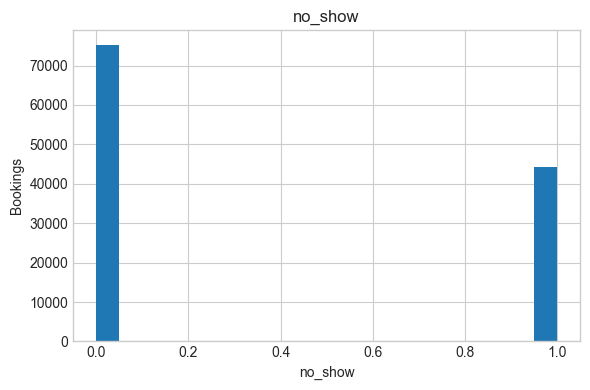

In [23]:
for column in numeric_integer_features:
    counts = df[column].value_counts(dropna=False).sort_index()
    axis = counts.plot(kind="bar", figsize=(6, 4))
    axis.bar_label(axis.containers[0], fmt="%d")
    axis.margins(y=0.15)
    axis.set_title(column)
    axis.set_xlabel(column)
    axis.set_ylabel("Bookings")
    plt.tight_layout()
    plt.show()

for column in numeric_float_features + target:
    plt.figure(figsize=(6, 4))
    plt.hist(numeric_analysis_df[column].dropna(), bins=20)
    plt.title(column)
    plt.xlabel(column)
    plt.ylabel("Bookings")
    plt.tight_layout()
    plt.show()


The summary statistics and plots for numeric features and the target variable inform the following decisions:

| Field | Finding | Cleaning action |
| --- | --- | --- |
| `no_show` | There are 44,224 no-shows and 75,166 shows among 119,390 bookings with an observed target, giving a no-show rate of 37.04%. There is one missing target value, no negative target values, and the target is binary. | Remove the missing target row before model training. Account for the class distribution when selecting metrics and interpreting predicted probabilities. |
| `price` | The parsed numeric price has a median of 815.32 and a maximum of 2,099.96 among 94,509 non-missing values. | Retain the parsed amount and currency for the existing price-conversion and feature-engineering nodes; handle missing values in downstream preprocessing. |


### 3.2 Univariate data analysis for categorical features

Inspecting unique values for each categorical feature.


In [24]:
for column in categorical_nominal_features:
    print(f"\n{column}:")
    print(df[column].dropna().unique())



branch:
['Changi' 'Orchard']

booking_month:
['November' 'August' 'March' 'September' 'July' 'January' 'October' 'June'
 'December' 'April' 'May' 'February']

arrival_month:
['June' 'November' 'February' 'October' 'September' 'March' 'May' 'August'
 'July' 'January' 'April' 'December' 'ApRiL' 'OcTobeR' 'JuNe' 'JulY'
 'ApriL' 'OctOber' 'DecembEr' 'SeptEmber' 'JanUary' 'JUne' 'FeBruary'
 'JanuarY' 'DEcember' 'SePtember' 'DecembeR' 'MaY' 'NoVember' 'JUly'
 'JunE' 'JuLy' 'FebrUary' 'NOvember' 'SeptemBer' 'OctobeR' 'DecemBer'
 'MarCh' 'AuguSt' 'AugusT' 'APril' 'SepTember' 'NovembEr' 'FEbruary'
 'DeceMber' 'AuGust' 'SepteMber' 'FebruaRy' 'OctoBer' 'JanuaRy' 'MarcH'
 'ApRil' 'AUgust' 'JanuAry' 'NOveMber' 'MaRch' 'AprIl' 'MAy' 'NovemBer'
 'DecEmber' 'MArch' 'JaNuary' 'NovembeR' 'SeptembEr' 'FebruarY'
 'SeptembeR' 'OcTober' 'DeCember' 'FebruAry' 'AugUst' 'NovEmber'
 'NoveMber' 'OctobEr' 'OCtober' 'SEptember' 'JAnuary' 'SeptEMber' 'MAY'
 'FebRuary' 'FeBruarY' 'OCTober' 'JUnE' 'DecEMber' 'Februa

Inspecting the unique values for the categorical features informs the following decisions:

| Field | Finding | Cleaning action |
| --- | --- | --- |
| `arrival_month` | The 12 month names appear with inconsistent casing, including values such as `April` and `ApRiL`. | Apply `standardize_month_columns` to normalise month labels before encoding. |

In [25]:
from hotel_no_show_prediction.pipelines.data_cleaning.nodes import (
    standardize_month_columns,
)

df = standardize_month_columns(df)


In [26]:
month_columns = [
    column for column in df.columns if column.endswith("_month")
]

specified_months = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
]

month_standardization_sanity_check = {
    column: df[column].dropna().isin(specified_months).all()
    for column in month_columns
}
month_standardization_sanity_check


{'booking_month': True, 'arrival_month': True, 'checkout_month': True}

Inspecting barplots for categorical features, including missing values.


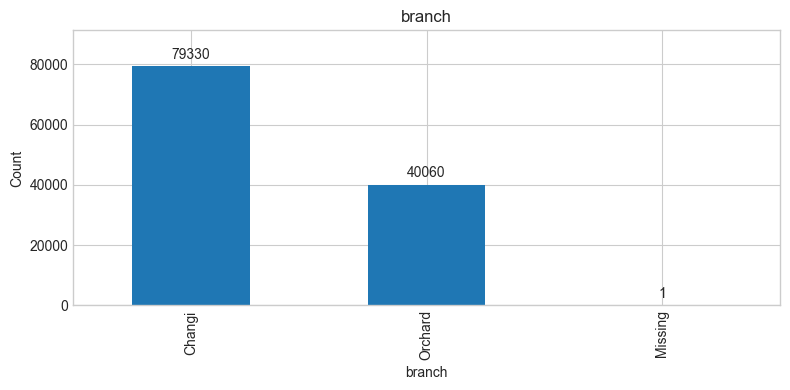

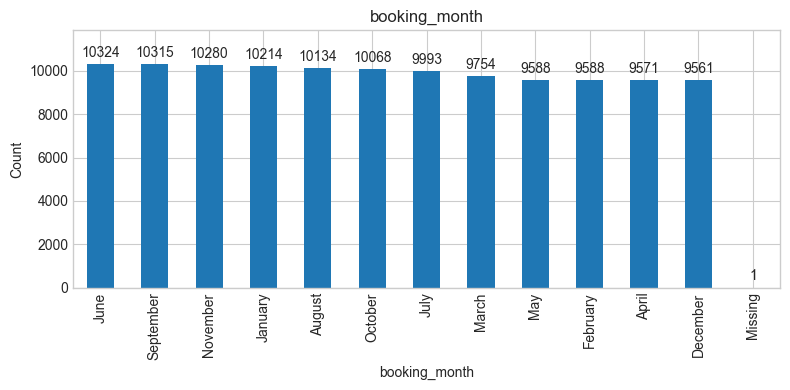

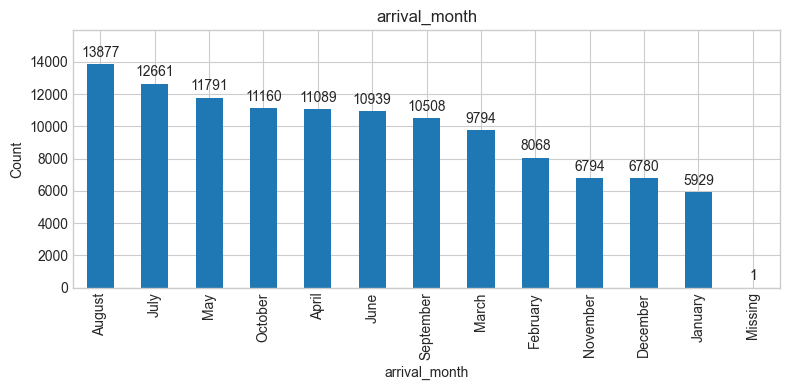

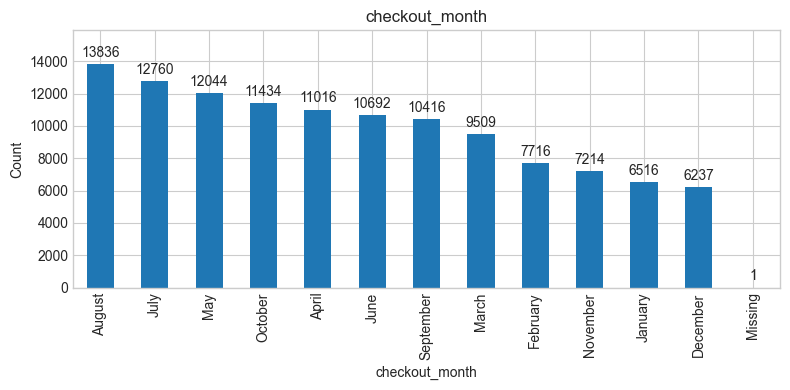

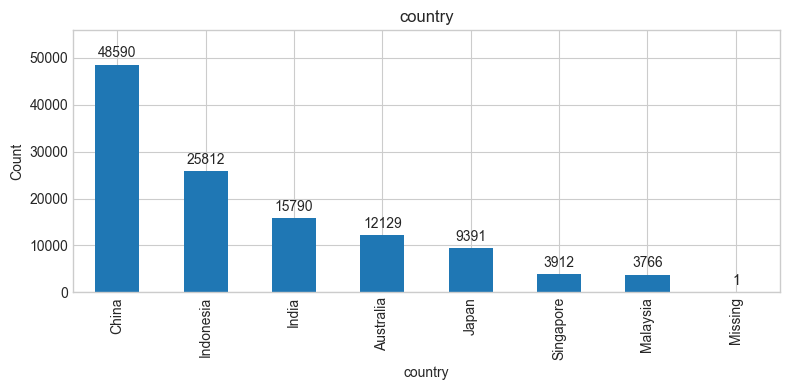

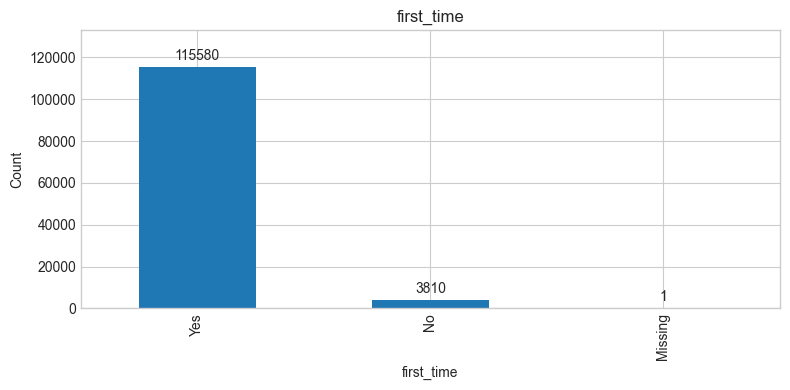

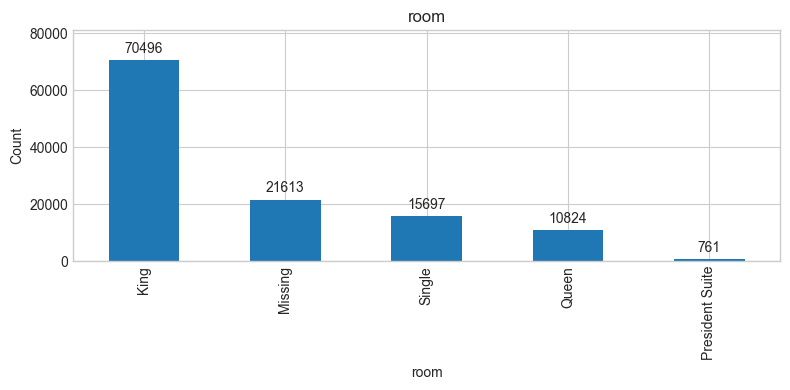

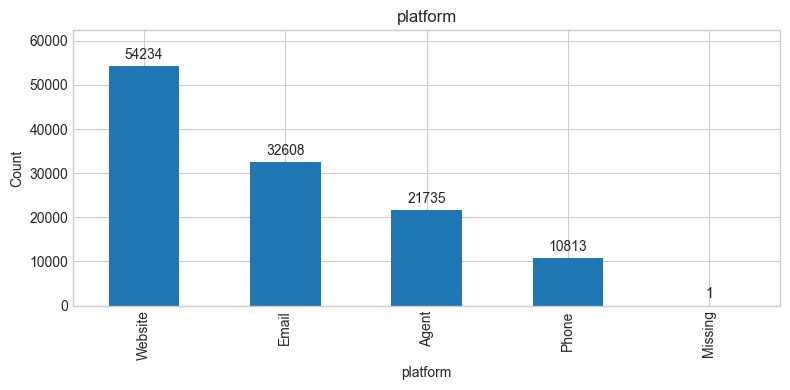

In [27]:
for column in categorical_plot_features:
    counts = df[column].fillna("Missing").value_counts()
    axis = counts.plot(kind="bar", figsize=(8, 4))
    axis.bar_label(axis.containers[0], fmt="%d", padding=3)
    axis.margins(y=0.15)
    axis.set_title(column)
    axis.set_xlabel(column)
    axis.set_ylabel("Count")
    plt.tight_layout()
    plt.show()


### 3.3. Univariate data analysis for engineered features

The following features are engineered:

| Engineered feature | Meaning |
| --- | --- |
| `price_amount_sgd` | Booking price converted to Singapore dollars. |
| `stay_length_nights` | Number of nights between the arrival and checkout dates. |
| `booking_to_arrival_month_gap` | Number of calendar months from the booking month to the arrival month. |
| `total_guests` | Total number of adults and children in the booking. |
| `price_per_guest` | Singapore-dollar booking price divided by the total number of guests. |
| `price_per_night` | Singapore-dollar booking price divided by the stay length in nights. |
| `price_per_guest_per_night` | Singapore-dollar booking price divided by total guests and stay length in nights. |


In [28]:
# create candidate engineered features using the exact pipeline node functions
from hotel_no_show_prediction.pipelines.feature_engineering.nodes import (
    add_booking_to_arrival_month_gap,
    add_price_per_guest,
    add_price_per_guest_per_night,
    add_price_per_night,
    add_stay_length_nights,
    add_total_guests,
    price_amount_usd_to_sgd,
)

analysis_df = df.copy()
analysis_df = price_amount_usd_to_sgd(analysis_df)
analysis_df = add_stay_length_nights(analysis_df)
analysis_df = add_booking_to_arrival_month_gap(analysis_df)
analysis_df = add_total_guests(analysis_df)
analysis_df = add_price_per_guest(analysis_df)
analysis_df = add_price_per_night(analysis_df)
analysis_df = add_price_per_guest_per_night(analysis_df)

engineered_numeric_features = [
    "price_amount_sgd",
    "stay_length_nights",
    "booking_to_arrival_month_gap",
    "total_guests",
    "price_per_guest",
    "price_per_night",
    "price_per_guest_per_night",
]
analysis_df[engineered_numeric_features].describe().T


,count,mean,std,min,25%,50%,75%,max
price_amount_sgd,94509.0,942.242501,264.061122,394.2135,818.12,905.8095,998.62,2099.96
stay_length_nights,113694.0,2.110903,2.174538,1.0,1.0,2.0,2.0,64.0
booking_to_arrival_month_gap,119390.0,5.001717,3.524724,0.0,2.0,5.0,8.0,11.0
total_guests,119390.0,2.292629,0.95463,1.0,2.0,2.0,3.0,5.0
price_per_guest,94509.0,491.536795,266.477547,132.7185,301.053333,425.9115,592.9335,2087.45
price_per_night,89958.0,620.842371,339.263264,12.864326,401.051813,490.030875,866.29875,2099.96
price_per_guest_per_night,89958.0,322.57196,240.914224,5.910245,155.024167,245.985833,426.670187,2087.45


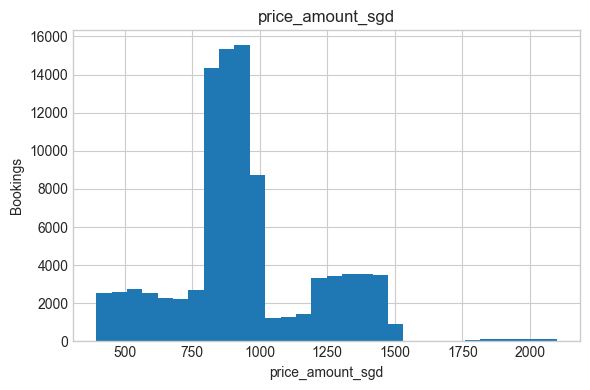

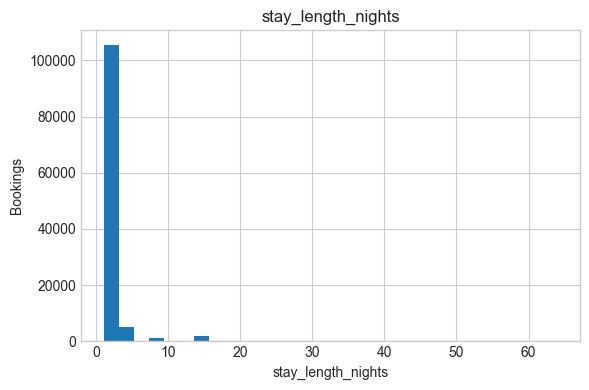

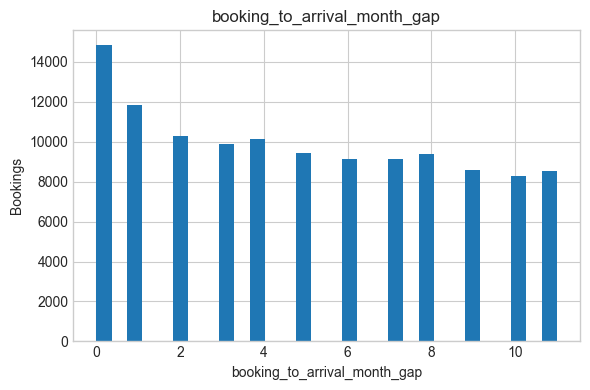

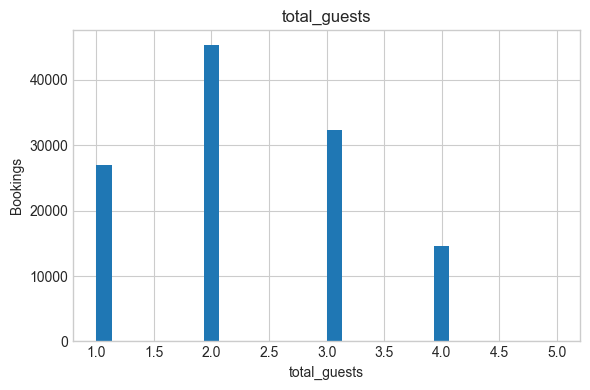

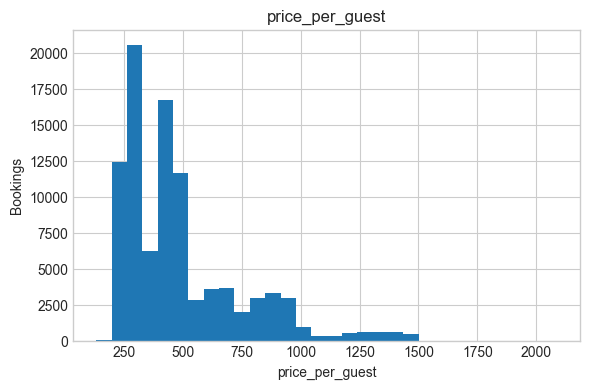

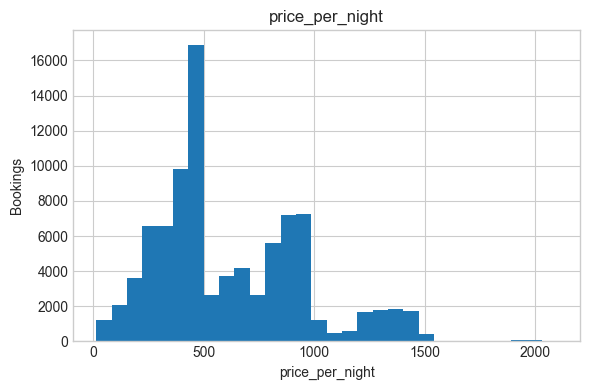

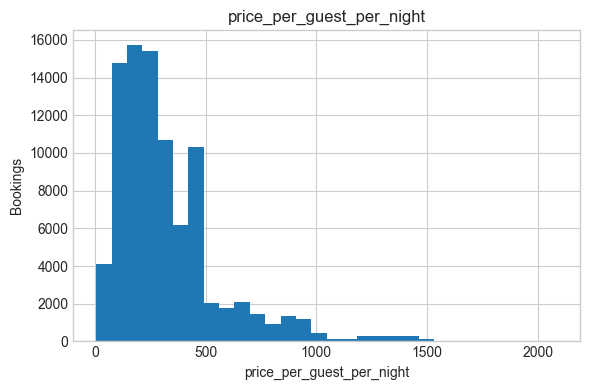

In [29]:
for column in engineered_numeric_features:
    plt.figure(figsize=(6, 4))
    plt.hist(analysis_df[column].dropna(), bins=30)
    plt.title(column)
    plt.xlabel(column)
    plt.ylabel("Bookings")
    plt.tight_layout()
    plt.show()


The summary statistics and histograms for the engineered features inform the following observations:

| Feature group | Finding | Interpretation |
| --- | --- | --- |
| Timing and guest counts | Median stay length is 2 nights, the booking-to-arrival gap is 5 months, and total guests is 2. | These features are concentrated around small discrete values. |
| Price-derived features | Medians are 905.81 SGD, 425.91 SGD per guest, 490.03 SGD per night, and 245.99 SGD per guest-night. | These features show more variation than the timing and guest-count features. |
| Missing engineered values | Missing values occur where price or calendar inputs are unavailable. | No additional cleaning action is introduced at this stage. |

## 4. Bivariate data analysis

The no-show target is categorical, so the bivariate analysis uses a chi-square test of independence for categorical features and a Mann-Whitney U test for numerical features. These tests identify candidate relationships with the target but do not establish causal effects or guarantee out-of-sample usefulness.

The plot type follows the analysis variable types. Categorical features versus the categorical `no_show` target use no-show-rate bar plots. Numeric integer features versus the target use discrete distribution bar plots, while numeric float features versus the target use box-and-whisker plots. Box-and-whisker plots are not used for categorical features because they would treat category labels as numeric values.


In [30]:
def fill_missing_categorical_labels(frame, categorical_features):
    frame = frame.copy()
    for column in categorical_features:
        frame[column] = frame[column].astype("string").fillna("Missing")
    return frame


df_for_plot = fill_missing_categorical_labels(
    df,
    categorical_plot_features,
)


### 4.1 Categorical features vs categorical target

We perform the chi-square test of independence to assess the association between each categorical feature and `no_show`. Significant associations (p-value < 0.05) are flagged in the `significant` column as shown below.


In [31]:
categorical_target_results = []

for feature in categorical_plot_features:
    contingency_table = pd.crosstab(
        df_for_plot[feature],
        df_for_plot[TARGET_COLUMN],
    )

    if contingency_table.shape[0] > 1 and contingency_table.shape[1] > 1:
        statistic, p_value, _, _ = chi2_contingency(contingency_table)
    else:
        statistic, p_value = float("nan"), float("nan")

    categorical_target_results.append({
        "feature": feature,
        "chi_square_statistic": statistic,
        "p_value": p_value,
    })

categorical_target_results = (
    pd.DataFrame(categorical_target_results)
    .sort_values("p_value")
    .reset_index(drop=True)
)
categorical_target_results["significant"] = categorical_target_results["p_value"] < 0.05
categorical_target_results.round(4)


,feature,chi_square_statistic,p_value,significant
0,branch,2224.9249,0.0000,True
1,country,14066.5793,0.0000,True
2,first_time,857.4063,0.0000,True
3,arrival_month,588.6918,0.0000,True
4,checkout_month,567.8999,0.0000,True
5,room,469.7504,0.0000,True
6,booking_month,205.5804,0.0000,True
7,platform,5.3817,0.1459,False


Inspecting no-show-rate bar plots for categorical features that are significantly associated with `no_show`.


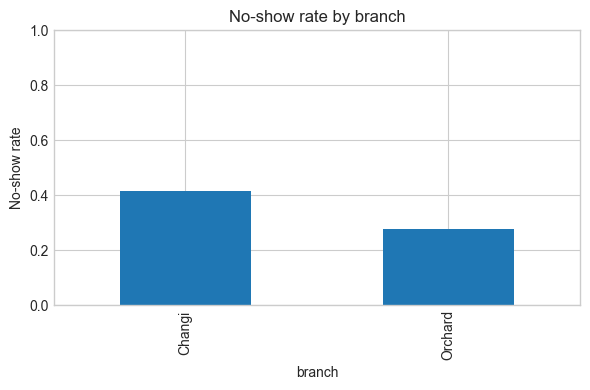

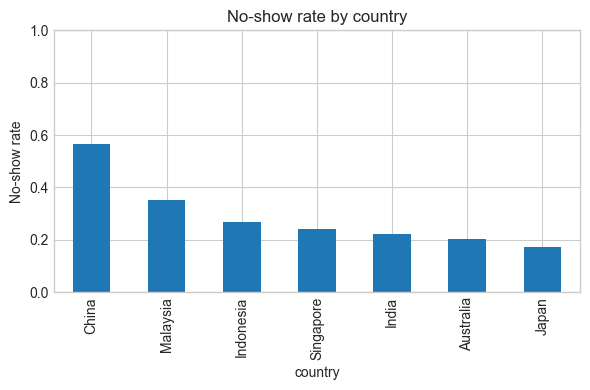

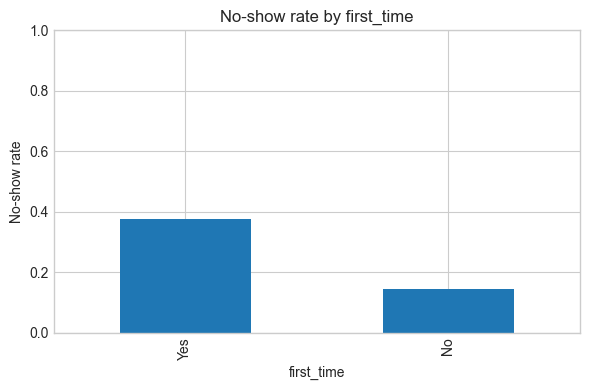

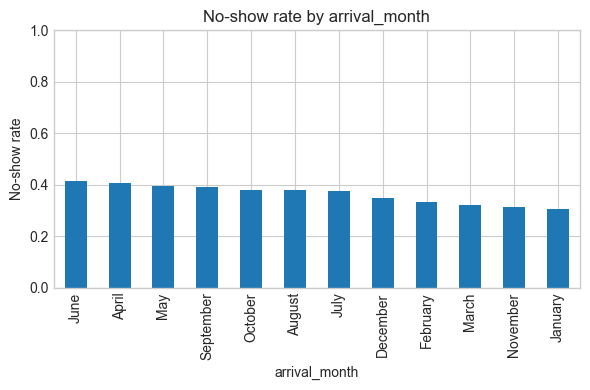

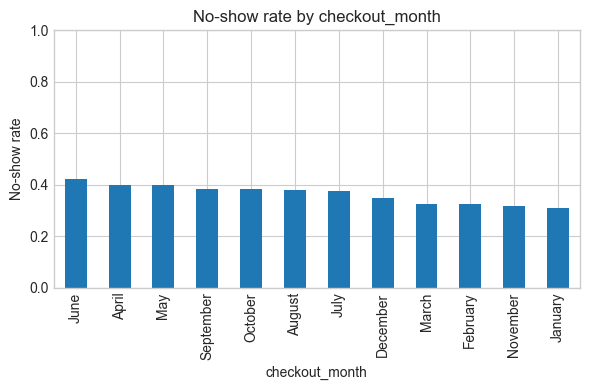

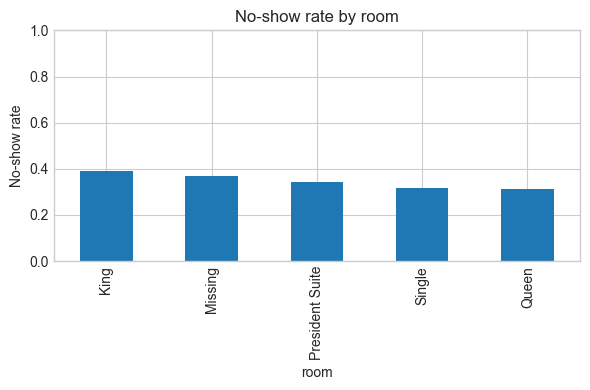

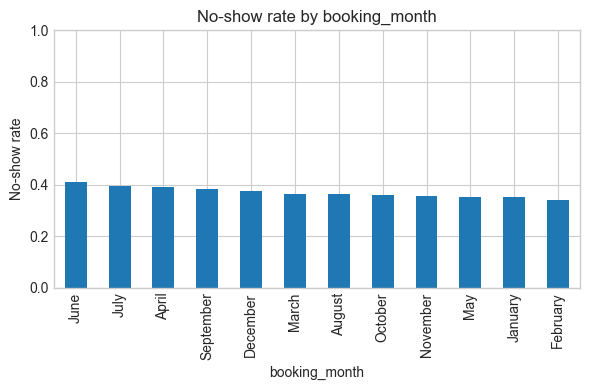

In [32]:
significant_categorical_features = categorical_target_results.loc[
    categorical_target_results["significant"],
    "feature",
].tolist()

for feature in significant_categorical_features:
    plt.figure(figsize=(6, 4))
    association_df = df_for_plot[[feature, TARGET_COLUMN]].dropna()
    no_show_rates = association_df.groupby(
        feature,
        observed=True,
    )[TARGET_COLUMN].mean().sort_values(ascending=False)
    no_show_rates.plot(kind="bar")
    plt.title(f"No-show rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("No-show rate")
    plt.ylim(0, 1)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()


The no-show-rate plots show the following observed comparisons:

| Feature | Lowest no-show rates | Highest no-show rates |
| --- | --- | --- |
| `branch` | Orchard: 27.8%. | Changi: 41.7%. |
| `country` | Japan: 17.1%; Australia: 20.2%; India: 22.0%. | China: 56.6%; Malaysia: 35.4%; Indonesia: 26.7%. |
| `first_time` | No: 14.5%. | Yes: 37.8%. |
| `arrival_month` | January: 30.5%; November: 31.2%; March: 32.2%. | June: 41.5%; April: 40.8%; May: 39.7%. |
| `checkout_month` | January: 30.8%; November: 31.9%; February: 32.5%. | June: 42.1%; April: 39.9%; May: 39.8%. |
| `room` | Queen: 31.4%. | King: 39.2%. |
| `booking_month` | February: 33.9%; January: 35.0%; May: 35.3%. | June: 40.9%; July: 39.6%; April: 39.2%. |

These comparisons describe observed associations in the sample and do not establish causal effects.


### 4.2 Numeric features vs categorical target

We perform the Mann–Whitney U test to assess the association between each numeric feature and the two `no_show` groups. Significant associations (p-value < 0.05) are flagged in the `significant` column as shown below.


In [33]:
numeric_association_features = numeric_integer_features + engineered_numeric_features
numeric_target_results = []

for feature in numeric_association_features:
    association_df = analysis_df[[feature, TARGET_COLUMN]].dropna()
    groups = [
        association_df.loc[
            association_df[TARGET_COLUMN] == target_value,
            feature,
        ].to_numpy(dtype=float)
        for target_value in sorted(association_df[TARGET_COLUMN].unique())
    ]

    if len(groups) == 2:
        statistic, p_value = mannwhitneyu(
            groups[0],
            groups[1],
            alternative="two-sided",
        )
    else:
        statistic, p_value = float("nan"), float("nan")

    numeric_target_results.append({
        "feature": feature,
        "mann_whitney_u_statistic": statistic,
        "p_value": p_value,
    })

numeric_target_results = (
    pd.DataFrame(numeric_target_results)
    .sort_values("p_value")
    .reset_index(drop=True)
)
numeric_target_results["significant"] = numeric_target_results["p_value"] < 0.05
numeric_target_results.round(4)


,feature,mann_whitney_u_statistic,p_value,significant
0,booking_to_arrival_month_gap,1.485803e+09,0.0000,True
1,price_per_guest_per_night,1.030025e+09,0.0000,True
2,price_per_night,1.026893e+09,0.0000,True
3,stay_length_nights,1.396803e+09,0.0000,True
4,price_per_guest,1.108171e+09,0.0000,True
5,price_amount_sgd,1.100614e+09,0.0000,True
6,total_guests,1.617547e+09,0.0000,True
7,num_children,1.627796e+09,0.0000,True
8,checkout_day,1.535400e+09,0.0000,True
9,num_adults,1.637417e+09,0.0000,True


Inspecting discrete distribution bar plots for significant integer features and box-and-whisker plots for significant float features.


<Figure size 600x400 with 0 Axes>

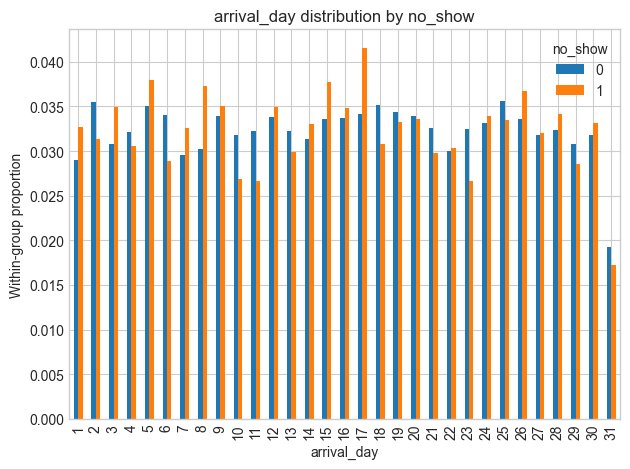

<Figure size 600x400 with 0 Axes>

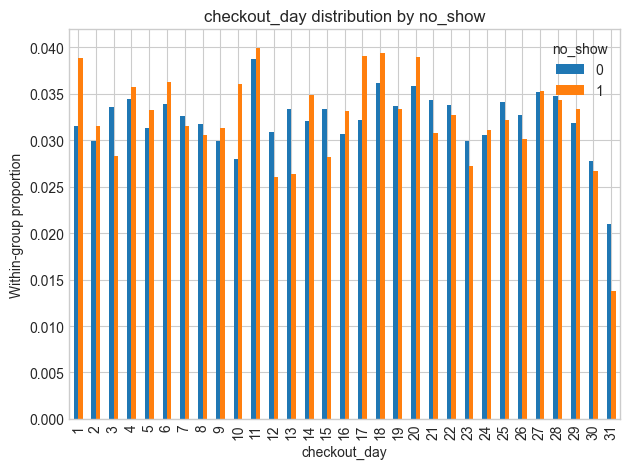

<Figure size 600x400 with 0 Axes>

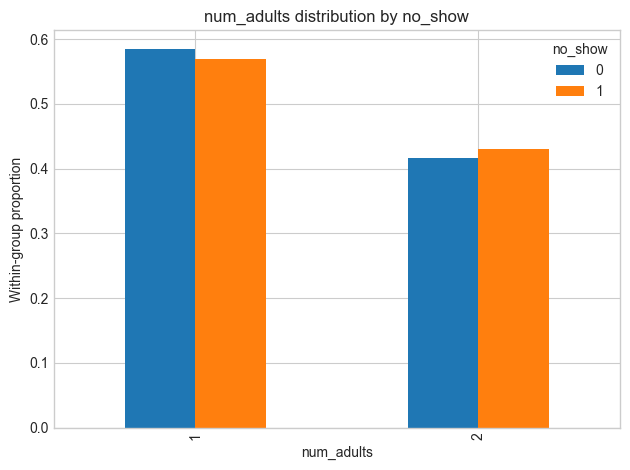

<Figure size 600x400 with 0 Axes>

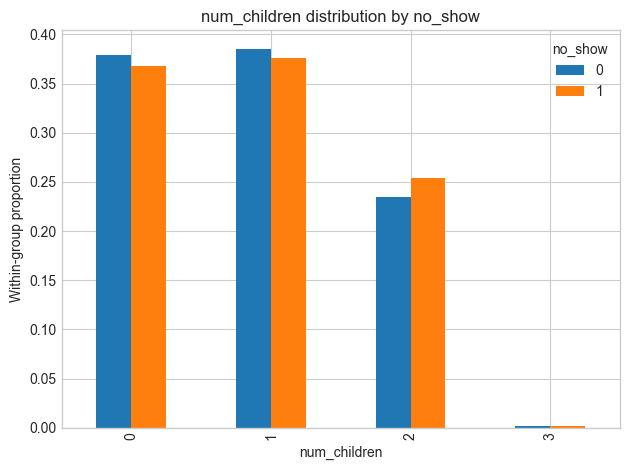

<Figure size 600x400 with 0 Axes>

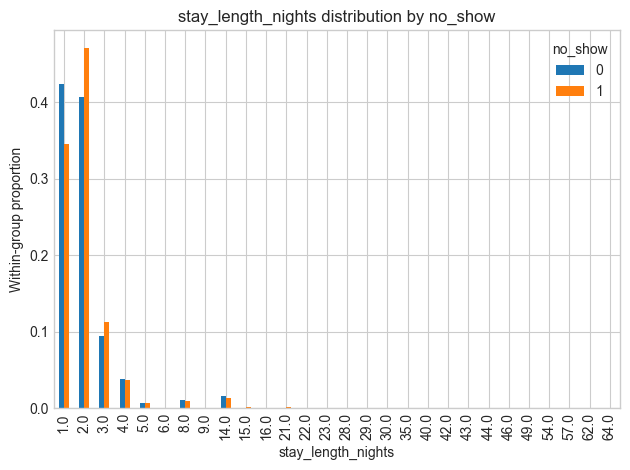

<Figure size 600x400 with 0 Axes>

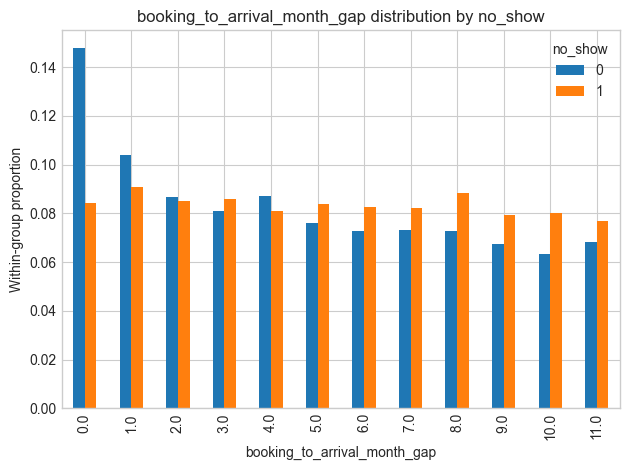

<Figure size 600x400 with 0 Axes>

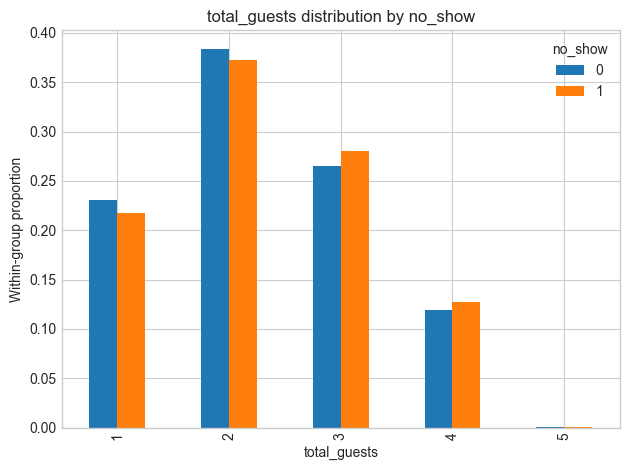

In [34]:
significant_numeric_features = numeric_target_results.loc[
    numeric_target_results["significant"],
    "feature",
].tolist()
integer_plot_feature_candidates = numeric_integer_features + [
    "stay_length_nights",
    "booking_to_arrival_month_gap",
    "total_guests",
]
integer_plot_features = [
    feature
    for feature in integer_plot_feature_candidates
    if feature in significant_numeric_features
]

for feature in integer_plot_features:
    plt.figure(figsize=(6, 4))
    association_df = analysis_df[[feature, TARGET_COLUMN]].dropna()
    distribution = pd.crosstab(
        association_df[feature],
        association_df[TARGET_COLUMN],
        normalize="columns",
    )
    distribution.plot(kind="bar")
    plt.title(f"{feature} distribution by no_show")
    plt.xlabel(feature)
    plt.ylabel("Within-group proportion")
    plt.legend(title="no_show")
    plt.tight_layout()
    plt.show()


<Figure size 600x400 with 0 Axes>

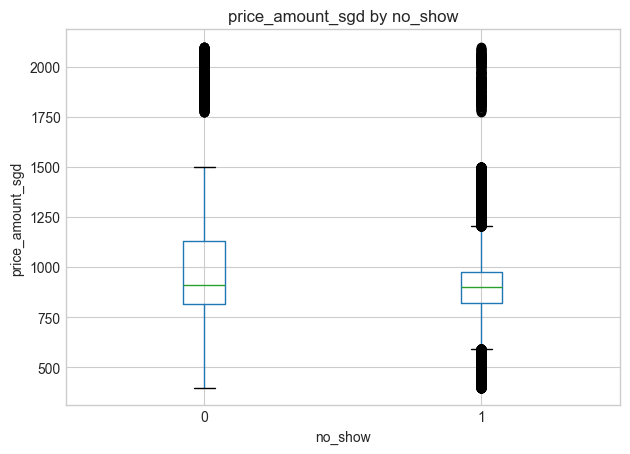

<Figure size 600x400 with 0 Axes>

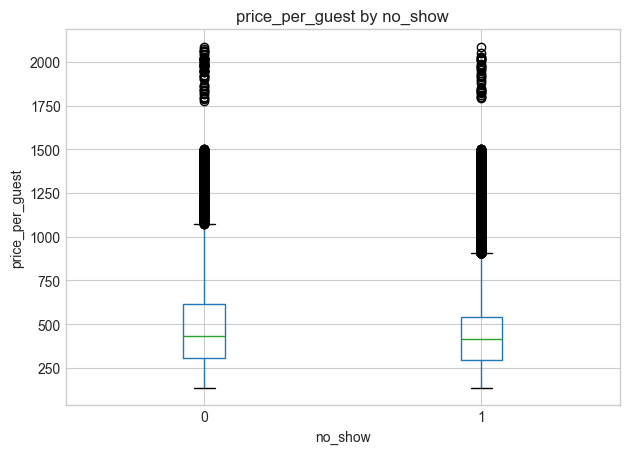

<Figure size 600x400 with 0 Axes>

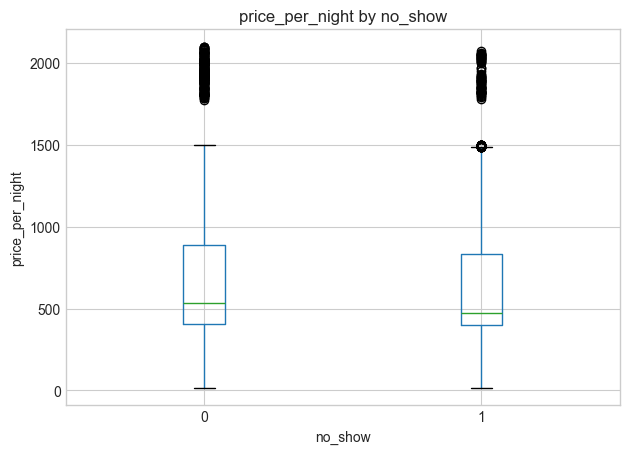

<Figure size 600x400 with 0 Axes>

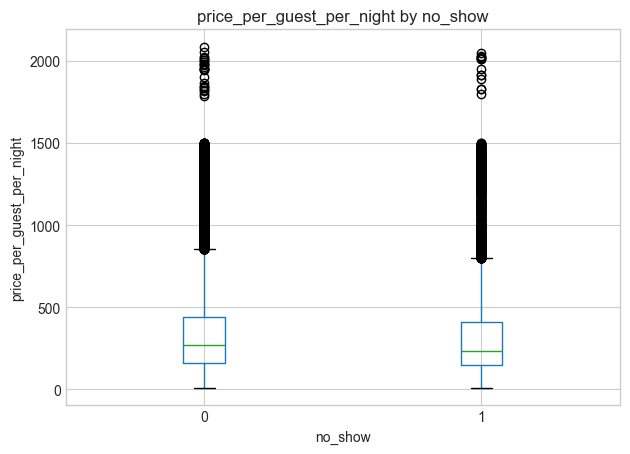

In [35]:
float_plot_feature_candidates = [
    "price_amount_sgd",
    "price_per_guest",
    "price_per_night",
    "price_per_guest_per_night",
]
float_plot_features = [
    feature
    for feature in float_plot_feature_candidates
    if feature in significant_numeric_features
]

for feature in float_plot_features:
    plt.figure(figsize=(6, 4))
    association_df = analysis_df[[feature, TARGET_COLUMN]].dropna()
    association_df.boxplot(column=feature, by=TARGET_COLUMN)
    plt.suptitle("")
    plt.title(f"{feature} by no_show")
    plt.xlabel("no_show")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()


The numeric plots show the following observed median comparisons:

| Feature | Shows median | No-shows median | Higher median |
| --- | ---: | ---: | --- |
| `booking_to_arrival_month_gap` | 4 | 5 | No-shows |
| `price_per_guest_per_night` | 268.28 | 233.54 | Shows |
| `price_per_night` | 533.86 | 473.73 | Shows |
| `price_per_guest` | 431.66 | 416.66 | Shows |
| `price_amount_sgd` | 911.65 | 898.19 | Shows |

The medians for `stay_length_nights`, `total_guests`, `num_children`, `checkout_day`, `num_adults`, and `arrival_day` look equal across the two groups.
